In [1]:
import numpy as np
import pandas as pd

# Cleaning

In [2]:
health = pd.read_csv('Data/la_health.csv')
g_cover = pd.read_csv('Data/g_cover.csv')
wealth = pd.read_csv('Data/wealth.csv')


In [3]:
# Eliminating white space and capitals in column titles for ease
def clean_text(s):
    return s.astype("string").str.strip().str.lower()

wealth.columns = clean_text(wealth.columns)
health.columns = clean_text(health.columns)
g_cover.columns = clean_text(g_cover.columns)

In [4]:
# Fixing incorrect column names
g_cover = g_cover.rename(columns={
    'lb_code': 'borough',
    'lb_name': 'lb_code'
})

# Simplifying and matching column names for borough names
health = health.rename(columns={
    'local authority district name (2024)': 'borough',
})

wealth = wealth.rename(columns={
    'local authority district name (2024)': 'borough',
    
})



In [5]:
health.columns

Index(['local authority district code (2024)', 'borough',
       'health deprivation and disability - average rank',
       'health deprivation and disability - rank of average rank',
       'health deprivation and disability - average score',
       'health deprivation and disability - rank of average score',
       'health deprivation and disability - proportion of lsoas in most deprived 10% nationally',
       'health deprivation and disability - rank of proportion of lsoas in most deprived 10% nationally'],
      dtype='str')

In [ ]:
# Checking both datasets are the same length

len(health['borough']) - len(wealth['borough']) 

0

In [ ]:
# Creatng a list of the London Boroughs

boroughs = g_cover['borough'] 


In [8]:
N = len(health['borough']) # Length of health and wealth borough columns, both are the same length so only one needed
G = len(g_cover) # Length of g_cover borough dataset (actual number of boroughs in London)


# Creating a list of all rows that match the values in 'boroughs' and setting the datasets to only contain those rows

lbs_h = health['borough'].isin(boroughs)
health = health[lbs_h]

lbs_w = wealth['borough'].isin(boroughs)
wealth = wealth[lbs_w]





In [9]:
# Selecting only relevant columns for wealth and health
# Average score used as it is the best indicator for each dataset for the variable I want to identify

wealth = wealth.loc[:, [
    'borough', 'income - average score'
]]

health = health.loc[:, [
    'borough', 'health deprivation and disability - average score'
]]

# Merging wealth and health datasets

lb_demo = pd.merge(wealth, health, how='inner', on='borough')

# Merging demographics (wealth and health) dataset with green and blue cover dataset

data = pd.merge(g_cover, lb_demo, how='inner', on='borough')

In [10]:
data = data.assign(
    health_score=data['health deprivation and disability - average score']*-1,
    wealth_score=data['income - average score']*-1
).drop(columns=['income - average score', 'health deprivation and disability - average score'])

In [36]:
#Checking for any null values

print(' --------\nNull Values\n --------', '\n', data.isna().sum())


 --------
Null Values
 -------- 
 borough                    0
lb_code                    0
borough_area_hectare       0
green_area_hectare         0
blue _area_hectare         0
green+blue_area_hectare    0
percent_green              0
percent_blue               0
percent_green+blue         0
health_score               0
wealth_score               0
dtype: int64


In [11]:
# Writing cleaned dataset to a file
data.to_csv('Data/borough_demographics.csv')

# Initial Analysis

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

data.columns

Index(['borough', 'lb_code', 'borough_area_hectare', 'green_area_hectare',
       'blue _area_hectare', 'green+blue_area_hectare', 'percent_green',
       'percent_blue', 'percent_green+blue', 'health_score', 'wealth_score'],
      dtype='str')

In [40]:
data1 = data.loc[:,[
    'green_area_hectare', 'blue _area_hectare', 'green+blue_area_hectare',
    'percent_green', 'percent_blue', 'percent_green+blue',
    'wealth_score', 'health_score', 'borough_area_hectare'
]]

In [41]:
data1.describe()

,green_area_hectare,blue _area_hectare,green+blue_area_hectare,percent_green,percent_blue,percent_green+blue,wealth_score,health_score,borough_area_hectare
count,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000
mean,2488.764062,142.140625,2630.904688,44.003125,3.261563,47.264375,-0.264937,0.273594,4914.585312
std,2261.739047,144.501507,2309.214403,12.813712,2.978609,11.729962,0.083482,0.439584,3294.747720
min,17.610000,3.950000,41.920000,5.590000,0.130000,13.310000,-0.401000,-0.602000,314.940000
25%,1080.795000,31.080000,1180.600000,38.510000,0.895000,41.015000,-0.307500,-0.055500,2901.115000
50%,1780.960000,58.485000,1915.365000,43.415000,2.270000,47.465000,-0.266000,0.289500,3869.300000
75%,2853.265000,244.965000,3126.405000,53.102500,5.180000,55.150000,-0.202250,0.562000,5712.932500
max,10262.640000,437.520000,10319.600000,68.360000,11.750000,69.490000,-0.066000,1.382000,15013.490000


### Correlation

.corr() looks for correlation between variables. We invert the health scores and wealth scores and assign them health and wealth for ease of interpretation. High scores reflect low health or wealth so this change allows easier identification of a positive or negative correlation between green/blue space and health and wealth.

<body style="background-color:powderblue;">

<h3>To do</h3>

<form>
  <div>
    <input
      type="checkbox"
      id="action_1"
    />
    <label for="action_1">Why .corr()</label>
    </div>
    <div>
    <input
    type='checkbox'
    id='action_2'
    />
    <label for='action_2'>Mechanism of .corr()</label>
  </div>


</form>

</body>

In [17]:
data1.corr()

,green_area_hectare,blue _area_hectare,green+blue_area_hectare,percent_green,percent_blue,percent_green+blue,wealth_score,health_score
green_area_hectare,1.000000,0.300049,0.998217,0.805117,-0.235154,0.819877,0.230829,0.414180
blue _area_hectare,0.300049,1.000000,0.356456,0.183336,0.672906,0.371049,-0.129505,-0.038669
green+blue_area_hectare,0.998217,0.356456,1.000000,0.800037,-0.188212,0.826240,0.217979,0.403246
percent_green,0.805117,0.183336,0.800037,1.000000,-0.465088,0.974424,0.122321,0.477506
percent_blue,-0.235154,0.672906,-0.188212,-0.465088,1.000000,-0.254258,-0.148898,-0.255369
percent_green+blue,0.819877,0.371049,0.826240,0.974424,-0.254258,1.000000,0.095769,0.456843
wealth_score,0.230829,-0.129505,0.217979,0.122321,-0.148898,0.095769,1.000000,0.703287
health_score,0.414180,-0.038669,0.403246,0.477506,-0.255369,0.456843,0.703287,1.000000


### Correlation output intrepretation

We can see a positive correlation between the health and wealth values and the percentage of the borough made up of a combination of green and blue space. Looking at the % variables for only green and blue space we can see a negative correlation between both percent of the borough comprised of blue space and the total area of blue space with both health and wealth, however these values are small so are unlikely to indicate a statisticall informative relation between the variables. For green space we can see a high correlation between green space area and percentage with health (relative to the other relationships shown in the table), however there is a lower correlation between green space (% and area) and wealth.

The highest correlation is between wealth and health, reflecting poor health is often a result of economic inequality. The correlation between green space and health is likely due to areas with higher economic inequality having less funding and interest in maintaining and creating new green spaces (likely as a result of funding priorites being linked to combating underlying drivers of economic inequality, like a lack of jobs or underfunded education systems).


<body style="background-color:powderblue;">

<h3>To do</h3>

<form>
  <div>
    <input
      type="checkbox"
      id="action_1"
    />
    <label for="action_1">health-wealth correlation further depth and add figure</label>
    </div>
    <div>
    <input
    type='checkbox'
    id='action_2'
    />
    <label for='action_2'>Explicitly state moderate correlation of 0.4 between green and health/wealth</label>
  </div>
  <div>
  <input
  type='checkbox'
  id='action_3'
  />
  <label for='action_3'>blue correlations very weak</label>
  </div>
  <div>
  <input
  type='checkbox'
  id='action_4'
  />
  <label for='action_4'>cite assumptions of underlying causes for associations where stated</label>
  <div>
  <input
  type='checkbox'
  id='action_5'
  />
  <label for='action_5'>talk about city of london</label>





</form>

</body>

In [ ]:
x = data['wealth_score']
y = data['health_score']
z = data['percent_green+blue']



In [39]:
data.columns

Index(['borough', 'lb_code', 'borough_area_hectare', 'green_area_hectare',
       'blue _area_hectare', 'green+blue_area_hectare', 'percent_green',
       'percent_blue', 'percent_green+blue', 'health_score', 'wealth_score'],
      dtype='str')

### Removing the City of London

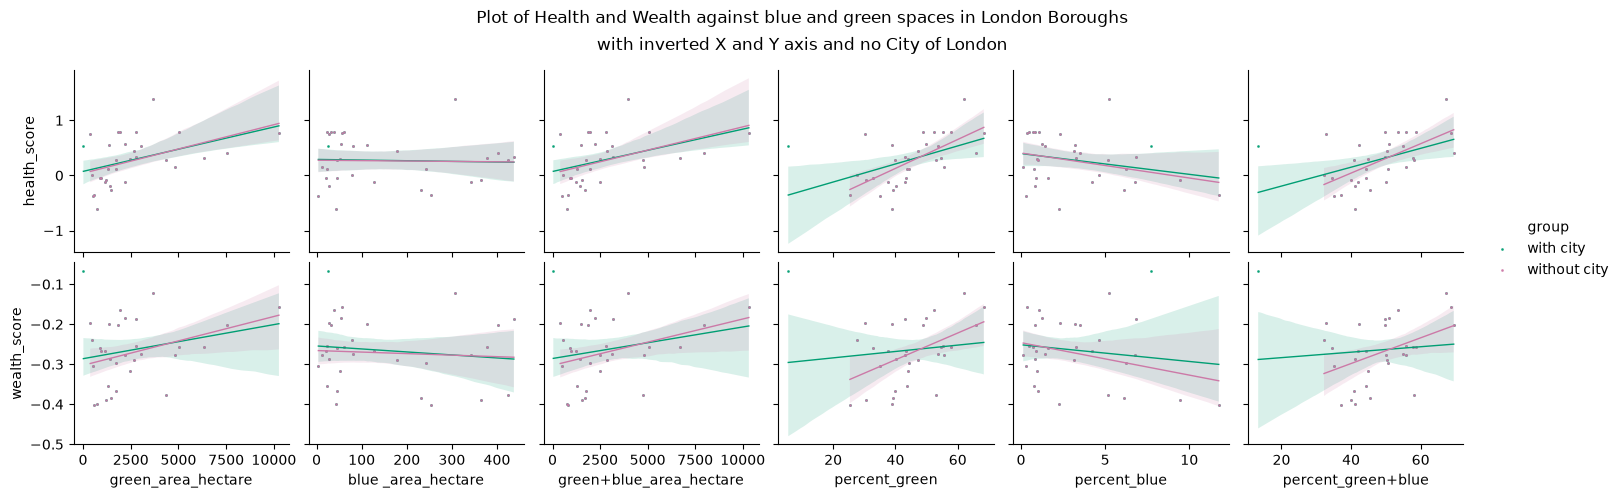

In [48]:
data_cl = data1.drop(index=31)

data1['group'] = 'with city'
data_cl['group'] = 'without city'

compared = pd.concat([data1, data_cl], ignore_index=True)

plot = sns.pairplot(data=compared,
             kind='reg', 
             y_vars = ['health_score', 'wealth_score'],
             x_vars = ['green_area_hectare', 'blue _area_hectare', 'green+blue_area_hectare',
                     'percent_green', 'percent_blue', 'percent_green+blue'],
             hue = 'group',
             palette = {
                 'with city': '#009E73',
                 'without city': '#CC79A7'
             },
             plot_kws={'scatter_kws': {'s': 1},
                       'line_kws': {'lw': 1}                        
                 
             })

#for ax in plot.axes[:, 0]:
#    ax=ax.invert_yaxis()

plot.fig.text(0.5,0.9, 'with inverted X and Y axis and no City of London', ha='center', fontsize=12)
plot.fig.subplots_adjust(top=0.86)
plt.suptitle('Plot of Health and Wealth against blue and green spaces in London Boroughs')
#plt.title('with inverted X and Y axis', y=1.9, x=-2.5)

plt.show()

## Comment on graph

In [19]:

data_cl.corr()

,green_area_hectare,blue _area_hectare,green+blue_area_hectare,percent_green,percent_blue,percent_green+blue,wealth_score,health_score
green_area_hectare,1.000000,0.279028,0.998156,0.848531,-0.191688,0.858787,0.359834,0.446756
blue _area_hectare,0.279028,1.000000,0.336808,0.123144,0.750104,0.348299,-0.072770,-0.023282
green+blue_area_hectare,0.998156,0.336808,1.000000,0.839784,-0.140535,0.864073,0.348224,0.436580
percent_green,0.848531,0.123144,0.839784,1.000000,-0.392004,0.964368,0.477833,0.643335
percent_blue,-0.191688,0.750104,-0.140535,-0.392004,1.000000,-0.134646,-0.308996,-0.297243
percent_green+blue,0.858787,0.348299,0.864073,0.964368,-0.134646,1.000000,0.425650,0.607405
wealth_score,0.359834,-0.072770,0.348224,0.477833,-0.308996,0.425650,1.000000,0.733931
health_score,0.446756,-0.023282,0.436580,0.643335,-0.297243,0.607405,0.733931,1.000000


In [24]:
# Regression Analysis

import statsmodels.api as sm
formula_string = "Q('health_score') ~ Q('percent_green') + Q('wealth_score')"

model_full = sm.formula.ols(formula = formula_string, data = data_cl)
model_full_fitted = model_full.fit()

print(model_full_fitted.summary())

                            OLS Regression Results                            
Dep. Variable:      Q('health_score')   R-squared:                       0.650
Model:                            OLS   Adj. R-squared:                  0.625
Method:                 Least Squares   F-statistic:                     25.96
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           4.20e-07
Time:                        11:15:21   Log-Likelihood:                -2.0763
No. Observations:                  31   AIC:                             10.15
Df Residuals:                      28   BIC:                             14.45
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              0.4383      0

## Comment on regression result

# Full Analaysis Plan